# Warning :
# Do "File -> Save a copy in Drive" before you start modifying the notebook, otherwise your modifications will not be saved.


In [1]:
import argparse
import os
import time

import PIL
from PIL import Image

import numpy as np
import torchvision
import pickle

import torch
import torch.nn as nn
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.utils.data
import torchvision.datasets as datasets
import torchvision.models as models
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.autograd import Variable

from sklearn.svm import LinearSVC

# Partie 1 : Architecture VGG16

In [2]:
#!wget https://github.com/cdancette/deep-learning-polytech-tp6-7/raw/master/tp8/imagenet_classes.pkl
!wget https://github.com/rdfia/rdfia.github.io/raw/master/data/3-a/imagenet_classes.pkl

# Bonus : Classifiez des exemples avec vgg16 et commentez le résultat dans votre rapport.
!wget --content-disposition https://unsplash.com/photos/gKXKBY-C-Dk/download?force=true -O cat.jpg
!wget --content-disposition https://unsplash.com/photos/qO-PIF84Vxg/download?force=true -O dog.jpg
!wget --content-disposition https://unsplash.com/photos/I_5NnUjIi6c/download?force=true -O tower.jpg

--2025-11-19 15:08:10--  https://github.com/rdfia/rdfia.github.io/raw/master/data/3-a/imagenet_classes.pkl
Resolving github.com (github.com)... 140.82.116.3
Connecting to github.com (github.com)|140.82.116.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/rdfia/rdfia.github.io/master/data/3-a/imagenet_classes.pkl [following]
--2025-11-19 15:08:11--  https://raw.githubusercontent.com/rdfia/rdfia.github.io/master/data/3-a/imagenet_classes.pkl
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 35454 (35K) [text/plain]
Saving to: ‘imagenet_classes.pkl’

imagenet_classes.pk 100%[===================>]  34.62K  --.-KB/s    in 0.002s  

2025-11-19 15:08:11 (15.1 MB/s) - ‘imagenet_classes.pkl’ saved [35454

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 174MB/s]


Predicted class index: 517
Predicted class label: crane


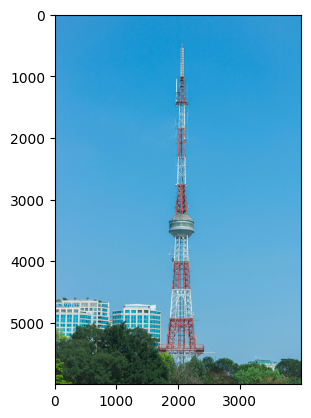

In [3]:
nameim = "tower"+".jpg"
img = Image.open(nameim)
plt.imshow(img)

# Loading ImageNet classes
imagenet_classes = pickle.load(open('imagenet_classes.pkl', 'rb'))

# Normalization
img = img.resize((224, 224), Image.BILINEAR)
img = np.array(img, dtype=np.float32) / 255
img = img.transpose((2, 0, 1))
# ImageNet mean/std
mu = torch.Tensor([0.485, 0.456, 0.406])
sigma = torch.Tensor([0.229, 0.224, 0.225])
# Expand mu & sigma to match image size
# YOUR CODE HERE
# compute the normalized image with mean ImageNet image
# img = YOUR CODE HERE
# Normalize

mu = mu.view(3, 1, 1)
sigma = sigma.view(3, 1, 1)

img = torch.from_numpy(img)
img = (img - mu) / sigma


# Loding pre-trained VGG
vgg16 = torchvision.models.vgg16(pretrained=True)
vgg16.eval()

# Forward pass on VGG
img = np.expand_dims(img, 0)
x = torch.Tensor(img)
y = vgg16(x) # TODO calcul forward
y = y.detach().numpy()# transformation en array numpy

# Get prediction (i.e., ImageNet class label)
# YOUR CODE HERE
pred_idx = np.argmax(y, axis=1)[0]
print("Predicted class index:", pred_idx)
print("Predicted class label:", imagenet_classes[pred_idx])

# Partie 2: Transfer Learning avec VGG16 sur 15 Scene

In [4]:
#!wget https://github.com/cdancette/deep-learning-polytech-tp6-7/raw/master/tp8/15ScenesData.zip
!wget https://github.com/rdfia/rdfia.github.io/raw/master/data/3-a/15ScenesData.zip

!unzip 15ScenesData.zip

--2025-11-19 15:09:12--  https://github.com/rdfia/rdfia.github.io/raw/master/data/3-a/15ScenesData.zip
Resolving github.com (github.com)... 140.82.116.4
Connecting to github.com (github.com)|140.82.116.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/rdfia/rdfia.github.io/master/data/3-a/15ScenesData.zip [following]
--2025-11-19 15:09:13--  https://raw.githubusercontent.com/rdfia/rdfia.github.io/master/data/3-a/15ScenesData.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 86520868 (83M) [application/zip]
Saving to: ‘15ScenesData.zip’

15ScenesData.zip    100%[===================>]  82.51M   238MB/s    in 0.3s    

2025-11-19 15:09:15 (238 MB/s) - ‘15ScenesData.zip’ saved [86520868/86520868]

In [ ]:
ls 15SceneData/test/bedroom/

image_0003.jpg  image_0042.jpg  image_0082.jpg  image_0124.jpg  image_0170.jpg
image_0004.jpg  image_0043.jpg  image_0084.jpg  image_0128.jpg  image_0175.jpg
image_0006.jpg  image_0047.jpg  image_0086.jpg  image_0130.jpg  image_0176.jpg
image_0007.jpg  image_0049.jpg  image_0087.jpg  image_0131.jpg  image_0180.jpg
image_0008.jpg  image_0050.jpg  image_0088.jpg  image_0134.jpg  image_0182.jpg
image_0011.jpg  image_0052.jpg  image_0090.jpg  image_0135.jpg  image_0189.jpg
image_0013.jpg  image_0053.jpg  image_0092.jpg  image_0138.jpg  image_0190.jpg
image_0014.jpg  image_0054.jpg  image_0093.jpg  image_0140.jpg  image_0191.jpg
image_0016.jpg  image_0056.jpg  image_0095.jpg  image_0141.jpg  image_0192.jpg
image_0017.jpg  image_0059.jpg  image_0096.jpg  image_0142.jpg  image_0195.jpg
image_0018.jpg  image_0060.jpg  image_0097.jpg  image_0144.jpg  image_0196.jpg
image_0019.jpg  image_0062.jpg  image_0098.jpg  image_0148.jpg  image_0200.jpg
image_0020.jpg  image_0063.jpg  image_0103.jpg  imag

In [5]:
class VGG16relu7(nn.Module):
    def __init__(self, vgg16_base):
        super(VGG16relu7, self).__init__()
        self.features = nn.Sequential(*list(vgg16_base.features.children()))
        self.classifier = nn.Sequential(*list(vgg16_base.classifier.children())[:5])

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

In [6]:

PRINT_INTERVAL = 50
CUDA = True

def get_dataset(batch_size, path):

    # This function expands 3 times a gray level image
    # to transform it into an image RGB. Use it with transform.Lambda
    def duplicateChannel(img):
        img = img.convert('L')
        np_img = np.array(img, dtype=np.uint8)
        np_img = np.dstack([np_img, np_img, np_img])
        img = Image.fromarray(np_img, 'RGB')
        return img
    def resizeImage(img):
      return img.resize((224,224), Image.BILINEAR)

    #####################
    ## YOUR CODE HERE  ##
    mean = [0.485, 0.456, 0.406]
    std = [0.229, 0.224, 0.225]

    common_transform = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    #####################
    # Add pre-processing
    train_dataset = datasets.ImageFolder(path+'/train',
        transform=common_transform)
    val_dataset = datasets.ImageFolder(path+'/test',
        transform=common_transform)
    ####################
    ##      END        #
    ####################

    train_loader = torch.utils.data.DataLoader(train_dataset,
                        batch_size=batch_size, shuffle=False, pin_memory=CUDA, num_workers=2)
    val_loader = torch.utils.data.DataLoader(val_dataset,
                        batch_size=batch_size, shuffle=False, pin_memory=CUDA, num_workers=2)

    return train_loader, val_loader

In [10]:
def extract_features(data, model):
    #####################
    ## YOUR CODE HERE  ##
    #####################
    # init features matrices
    X_list = []
    y_list = []
    ####################
    ##      END        #
    ####################


    for i, (input, target) in enumerate(data):
        if i % PRINT_INTERVAL == 0:
            print('Batch {0:03d}/{1:03d}'.format(i, len(data)))
        if CUDA:
            input = input.cuda()

        with torch.no_grad():
            feats = model(input)
            feats = nn.functional.normalize(feats, p=2, dim=1)

        #####################
        ## YOUR CODE HERE  ##
        #####################

        feats = feats.cpu().numpy()
        targets = target.numpy()

        X_list.append(feats)
        y_list.append(targets)

    X = np.concatenate(X_list, axis=0)
    y = np.concatenate(y_list, axis=0)


        ####################
        ##      END        #
        ####################

    return X, y


def main(path="15SceneData", batch_size=8):
    print('Instanciation de VGG16')
    vgg16 = models.vgg16(pretrained=True)

    print('Instanciation de VGG16relu7')
    #####################
    ## YOUR CODE HERE  ##
    #####################
    # Remplacer par le modèle par un réseau tronqué pour faire de la feature extraction
    # On créera une nouvelle classe VGG16relu7 ici
    model = VGG16relu7(vgg16)

    ####################
    ##      END        #
    ####################

    model.eval()
    if CUDA: # si on fait du GPU, passage en CUDA
        cudnn.benchmark = True
        model = model.cuda()

    # On récupère les données
    print('Récupération des données')
    train, test = get_dataset(batch_size, path)

    # Extraction des features
    print('Feature extraction')
    X_train, y_train = extract_features(train, model)
    X_test, y_test = extract_features(test, model)

    #####################
    ## Votre code ici  ##
    #####################
    # Apprentissage et évaluation des SVM à faire
    print('Apprentissage des SVM')
    svm = LinearSVC(C=1.0)
    svm.fit(X_train, y_train)
    accuracy = svm.score(X_test, y_test)

    ####################
    ##      FIN        #
    ####################
    print('Accuracy = %f' % accuracy)



In [9]:
main("15SceneData", 8)

Instanciation de VGG16


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Instanciation de VGG16relu7
Récupération des données
Feature extraction
Batch 000/188
Batch 050/188
Batch 100/188
Batch 150/188
Batch 000/374
Batch 050/374
Batch 100/374
Batch 150/374
Batch 200/374
Batch 250/374
Batch 300/374
Batch 350/374
Apprentissage des SVM
Accuracy = 0.888107


In [11]:
# 2.4 change the revolutional layer: Relu6
class VGG16relu6(nn.Module):
    def __init__(self, base_vgg):
        super().__init__()
        self.features = nn.Sequential(*list(base_vgg.features.children()))
        self.classifier = nn.Sequential(*list(base_vgg.classifier.children())[:2])

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x


def main(path="15SceneData", batch_size=8):
    print('Loading VGG16...')
    vgg16 = models.vgg16(pretrained=True)

    print('Using relu6 feature extractor')
    model = VGG16relu6(vgg16)

    model.eval()
    if CUDA:
        model = model.cuda()

    print("Loading dataset...")
    train, test = get_dataset(batch_size, path)

    print("Extracting relu6 features...")
    X_train, y_train = extract_features(train, model)
    X_test, y_test = extract_features(test, model)

    print("Training SVM...")
    svm = LinearSVC(C=1.0)
    svm.fit(X_train, y_train)
    accuracy = svm.score(X_test, y_test)

    print("Accuracy:", accuracy)


main("15SceneData", 8)



Loading VGG16...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Using relu6 feature extractor
Loading dataset...
Extracting relu6 features...
Batch 000/188
Batch 050/188
Batch 100/188
Batch 150/188
Batch 000/374
Batch 050/374
Batch 100/374
Batch 150/374
Batch 200/374
Batch 250/374
Batch 300/374
Batch 350/374
Training SVM...
Accuracy: 0.9068676716917923


In [12]:
# 2.4 other pre-trained network: ResNet-50
import torch
import torch.nn as nn
from torchvision import models

class ResNet50Extractor(nn.Module):
    def __init__(self):
        super().__init__()
        base = models.resnet50(pretrained=True)
        self.features = nn.Sequential(*list(base.children())[:-1])

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return x
def main(path="15SceneData", batch_size=8):

    print("Instanciation de ResNet50")
    model = ResNet50Extractor()

    model.eval()
    if CUDA:
        model = model.cuda()

    print("Loading dataset...")
    train, test = get_dataset(batch_size, path)

    print("Extracting features (ResNet-50)...")
    X_train, y_train = extract_features(train, model)
    X_test, y_test = extract_features(test, model)

    print("Training SVM...")
    svm = LinearSVC(C=1.0)
    svm.fit(X_train, y_train)
    accuracy = svm.score(X_test, y_test)

    print("Accuracy =", accuracy)

main("15SceneData", 8)

Instanciation de ResNet50


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 84.6MB/s]


Loading dataset...
Extracting features (ResNet-50)...
Batch 000/188
Batch 050/188
Batch 100/188
Batch 150/188
Batch 000/374
Batch 050/374
Batch 100/374
Batch 150/374
Batch 200/374
Batch 250/374
Batch 300/374
Batch 350/374
Training SVM...
Accuracy = 0.9102177554438861


In [13]:
# other pre-trained network: DenseNet-121
class DenseNet121Extractor(nn.Module):
    def __init__(self):
        super().__init__()
        base = models.densenet121(pretrained=True)
        self.features = base.features
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x):
        x = self.features(x)
        x = torch.relu(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return x

def main(path="15SceneData", batch_size=8):

    print("Instanciation de DenseNet121")
    model = DenseNet121Extractor()

    model.eval()
    if CUDA:
        model = model.cuda()

    print("Loading dataset...")
    train, test = get_dataset(batch_size, path)

    print("Extracting features (DenseNet-121)...")
    X_train, y_train = extract_features(train, model)
    X_test, y_test = extract_features(test, model)

    print("Training SVM...")
    svm = LinearSVC(C=1.0)
    svm.fit(X_train, y_train)
    accuracy = svm.score(X_test, y_test)

    print("Accuracy =", accuracy)

main("15SceneData", 8)

Instanciation de DenseNet121


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 127MB/s]


Loading dataset...
Extracting features (DenseNet-121)...
Batch 000/188
Batch 050/188
Batch 100/188
Batch 150/188
Batch 000/374
Batch 050/374
Batch 100/374
Batch 150/374
Batch 200/374
Batch 250/374
Batch 300/374
Batch 350/374
Training SVM...
Accuracy = 0.911892797319933


In [16]:
# other pre-trained network: EfficientNet-B0
import torch
import torch.nn as nn
from torchvision import models

class EfficientNetB0Extractor(nn.Module):
    def __init__(self):
        super().__init__()
        base = models.efficientnet_b0(pretrained=True)

        self.features = base.features
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return x


def main(path="15SceneData", batch_size=8):

    print("Instanciation d'EfficientNet-B0")
    model = EfficientNetB0Extractor()

    model.eval()
    if CUDA:
        model = model.cuda()

    print("Loading dataset...")
    train, test = get_dataset(batch_size, path)

    print("Extracting features (EfficientNet-B0)...")
    X_train, y_train = extract_features(train, model)
    X_test, y_test = extract_features(test, model)

    print("Training SVM...")
    svm = LinearSVC(C=1.0)
    svm.fit(X_train, y_train)
    accuracy = svm.score(X_test, y_test)

    print("Accuracy =", accuracy)
main("15SceneData", 8)

Instanciation d'EfficientNet-B0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 20.5M/20.5M [00:00<00:00, 110MB/s] 


Loading dataset...
Extracting features (EfficientNet-B0)...
Batch 000/188
Batch 050/188
Batch 100/188
Batch 150/188
Batch 000/374
Batch 050/374
Batch 100/374
Batch 150/374
Batch 200/374
Batch 250/374
Batch 300/374
Batch 350/374
Training SVM...
Accuracy = 0.930318257956449


In [17]:
# 2.4 Tune the parameter C
import numpy as np
import torch
import torch.nn as nn
import torch.backends.cudnn as cudnn
from torchvision import datasets, transforms, models
from sklearn.svm import LinearSVC
import torch.nn.functional as F
from PIL import Image

PRINT_INTERVAL = 50
CUDA = True


class VGG16relu7(nn.Module):
    def __init__(self, base_vgg):
        super().__init__()
        self.features = nn.Sequential(*list(base_vgg.features.children()))
        self.classifier = nn.Sequential(*list(base_vgg.classifier.children())[:5])

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x


def get_dataset(batch_size, path):

    mean = [0.485, 0.456, 0.406]
    std = [0.229, 0.224, 0.225]

    common_transform = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

    train_dataset = datasets.ImageFolder(
        path + '/train',
        transform=common_transform
    )
    val_dataset = datasets.ImageFolder(
        path + '/test',
        transform=common_transform
    )

    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=False,
        pin_memory=CUDA,
        num_workers=0
    )
    val_loader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        pin_memory=CUDA,
        num_workers=0
    )

    return train_loader, val_loader


def extract_features(data, model):

    X_list, y_list = [], []

    for i, (input, target) in enumerate(data):
        if i % PRINT_INTERVAL == 0:
            print('Batch {0:03d}/{1:03d}'.format(i, len(data)))

        if CUDA:
            input = input.cuda()

        with torch.no_grad():
            feat = model(input)
            feat = F.normalize(feat, p=2, dim=1)

        X_list.append(feat.cpu().numpy())
        y_list.append(target.numpy())

    X = np.concatenate(X_list, axis=0)
    y = np.concatenate(y_list, axis=0)
    return X, y


def main(path="15SceneData", batch_size=8):

    print("Loading base VGG16...")
    base_vgg = models.vgg16(pretrained=True)

    print("Using VGG16 relu7 feature extractor")
    model = VGG16relu7(base_vgg)

    model.eval()
    if CUDA:
        model = model.cuda()
        cudnn.benchmark = True

    print("Loading dataset...")
    train_loader, test_loader = get_dataset(batch_size, path)

    print("Extracting relu7 features for train...")
    X_train, y_train = extract_features(train_loader, model)

    print("Extracting relu7 features for test...")
    X_test, y_test = extract_features(test_loader, model)

    print("Training SVM with C tuning...")
    best_acc = 0
    best_C = None

    for C in [0.01, 0.1, 1, 10]:
        clf = LinearSVC(C=C)
        clf.fit(X_train, y_train)
        acc = clf.score(X_test, y_test)
        print(f"C={C}, accuracy={acc:.4f}")

        if acc > best_acc:
            best_acc = acc
            best_C = C

    print("\nBest C =", best_C)
    print("Best accuracy =", best_acc)


if __name__ == "__main__":
    main()


Loading base VGG16...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Using VGG16 relu7 feature extractor
Loading dataset...
Extracting relu7 features for train...
Batch 000/188
Batch 050/188
Batch 100/188
Batch 150/188
Extracting relu7 features for test...
Batch 000/374
Batch 050/374
Batch 100/374
Batch 150/374
Batch 200/374
Batch 250/374
Batch 300/374
Batch 350/374
Training SVM with C tuning...
C=0.01, accuracy=0.8412
C=0.1, accuracy=0.8734
C=1, accuracy=0.8881
C=10, accuracy=0.8861

Best C = 1
Best accuracy = 0.888107202680067


In [20]:
# 2.4 ： adapt VGG16 directly to the 15 Scene
import os
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.backends.cudnn as cudnn
import torch.utils.data
import torchvision.datasets as datasets
import torchvision.models as models
import torchvision.transforms as transforms

PRINT_INTERVAL = 50
CUDA = True
NUM_CLASSES = 15
NUM_EPOCHS = 10
BATCH_SIZE = 8
LR = 1e-3
FINE_TUNE_ALL = False


def get_dataset(batch_size, path):

    def duplicateChannel(img):
        img = img.convert('L')
        np_img = np.array(img, dtype=np.uint8)
        np_img = np.dstack([np_img, np_img, np_img])
        img = Image.fromarray(np_img, 'RGB')
        return img

    def resizeImage(img):
        return img.resize((224, 224), Image.BILINEAR)

    mean = [0.485, 0.456, 0.406]
    std  = [0.229, 0.224, 0.225]

    transform = transforms.Compose([
        transforms.Lambda(duplicateChannel),
        transforms.Lambda(resizeImage),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

    train_dataset = datasets.ImageFolder(os.path.join(path, 'train'),
                                         transform=transform)
    val_dataset = datasets.ImageFolder(os.path.join(path, 'test'),
                                       transform=transform)

    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=batch_size,
        shuffle=True, num_workers=2, pin_memory=CUDA
    )
    val_loader = torch.utils.data.DataLoader(
        val_dataset, batch_size=batch_size,
        shuffle=False, num_workers=2, pin_memory=CUDA
    )

    return train_loader, val_loader


def build_vgg16_finetune(num_classes=NUM_CLASSES):
    print("Instanciation de VGG16 (pretrained)")
    vgg16 = models.vgg16(pretrained=True)

    in_features = vgg16.classifier[6].in_features
    vgg16.classifier[6] = nn.Linear(in_features, num_classes)

    if not FINE_TUNE_ALL:
        for param in vgg16.features.parameters():
            param.requires_grad = False
        for param in vgg16.classifier[:-1].parameters():
            param.requires_grad = False

    return vgg16


def train_one_epoch(model, loader, criterion, optimizer, epoch):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for i, (inputs, targets) in enumerate(loader):
        if CUDA:
            inputs = inputs.cuda()
            targets = targets.cuda()

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)

        if i % PRINT_INTERVAL == 0:
            print(f'Epoch [{epoch}] Batch {i:03d}/{len(loader):03d}')

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f'Epoch [{epoch}] Train loss = {epoch_loss:.4f}, '
          f'accuracy = {epoch_acc:.4f}')
    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in loader:
            if CUDA:
                inputs = inputs.cuda()
                targets = targets.cuda()

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(targets).sum().item()
            total += targets.size(0)

    loss = running_loss / total
    acc = correct / total
    return loss, acc

def main(path="15SceneData"):
    model = build_vgg16_finetune(NUM_CLASSES)

    if CUDA:
        cudnn.benchmark = True
        model = model.cuda()

    print("Récupération des données")
    train_loader, val_loader = get_dataset(BATCH_SIZE, path)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad,
                                  model.parameters()),
                           lr=LR)

    for epoch in range(1, NUM_EPOCHS + 1):
        train_one_epoch(model, train_loader, criterion, optimizer, epoch)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        print(f'Epoch [{epoch}] Val   loss = {val_loss:.4f}, '
              f'accuracy = {val_acc:.4f}')

    final_loss, final_acc = evaluate(model, val_loader, criterion)
    print('Final accuracy (fine-tuned VGG16) = {:.4f}'.format(final_acc))


if __name__ == "__main__":
    main()

Instanciation de VGG16 (pretrained)
Récupération des données


/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')
/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')


Epoch [1] Batch 000/188
Epoch [1] Batch 050/188
Epoch [1] Batch 100/188
Epoch [1] Batch 150/188
Epoch [1] Train loss = 0.7267, accuracy = 0.7633


/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')
/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')


Epoch [1] Val   loss = 0.3749, accuracy = 0.8777


...

Epoch [10] Batch 000/188
Epoch [10] Batch 050/188
Epoch [10] Batch 100/188
Epoch [10] Batch 150/188
Epoch [10] Train loss = 0.0944, accuracy = 0.9687


/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')
/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')


Epoch [10] Val   loss = 0.3340, accuracy = 0.8881


/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')
/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')


Final accuracy (fine-tuned VGG16) = 0.8881


In [22]:
# 2.4 ：methods for dimensionality reduction ： PCA dim 512
def main(path="15SceneData", batch_size=8):

    print("Loading pre-trained VGG16…")
    from torchvision.models import VGG16_Weights
    base_vgg = models.vgg16(weights=VGG16_Weights.IMAGENET1K_V1)

    print("Using VGG16 relu7 feature extractor")
    model = VGG16relu7(base_vgg)

    model.eval()
    if CUDA:
        model = model.cuda()
        cudnn.benchmark = True

    print("Loading dataset…")
    train_loader, test_loader = get_dataset(batch_size, path)

    print("Extracting relu7 features for train…")
    X_train, y_train = extract_features(train_loader, model)

    print("Extracting relu7 features for test…")
    X_test, y_test = extract_features(test_loader, model)

    # PCA reduction
    from sklearn.decomposition import PCA

    print("Applying PCA: 4096 → 512 …")
    pca = PCA(n_components=512, whiten=True)

    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    print("Train features:", X_train_pca.shape)
    print("Test  features:", X_test_pca.shape)


    print("Training SVM (C = 1.0)…")
    svm = LinearSVC(C=1.0)
    svm.fit(X_train_pca, y_train)

    accuracy = svm.score(X_test_pca, y_test)
    print("\nFinal accuracy =", accuracy)


if __name__ == "__main__":
    main()

Loading pre-trained VGG16…
Using VGG16 relu7 feature extractor
Loading dataset…
Extracting relu7 features for train…


/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')
/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')


Batch 000/188
Batch 050/188
Batch 100/188
Batch 150/188
Extracting relu7 features for test…


/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')
/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')


Batch 000/374
Batch 050/374
Batch 100/374
Batch 150/374
Batch 200/374
Batch 250/374
Batch 300/374
Batch 350/374
Applying PCA: 4096 → 512 …
Train features: (1500, 512)
Test  features: (2985, 512)
Training SVM (C = 1.0)…

Final accuracy = 0.8686767169179229


In [23]:
# 2.4 ：methods for dimensionality reduction ： PCA dim 256
def main(path="15SceneData", batch_size=8):

    print("Loading pre-trained VGG16…")
    from torchvision.models import VGG16_Weights
    base_vgg = models.vgg16(weights=VGG16_Weights.IMAGENET1K_V1)

    print("Using VGG16 relu7 feature extractor")
    model = VGG16relu7(base_vgg)

    model.eval()
    if CUDA:
        model = model.cuda()
        cudnn.benchmark = True

    print("Loading dataset…")
    train_loader, test_loader = get_dataset(batch_size, path)

    print("Extracting relu7 features for train…")
    X_train, y_train = extract_features(train_loader, model)

    print("Extracting relu7 features for test…")
    X_test, y_test = extract_features(test_loader, model)

    # PCA reduction
    from sklearn.decomposition import PCA

    print("Applying PCA: 4096 → 256 …")
    pca = PCA(n_components=256, whiten=True)

    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    print("Train features:", X_train_pca.shape)
    print("Test  features:", X_test_pca.shape)


    print("Training SVM (C = 1.0)…")
    svm = LinearSVC(C=1.0)
    svm.fit(X_train_pca, y_train)

    accuracy = svm.score(X_test_pca, y_test)
    print("\nFinal accuracy =", accuracy)


if __name__ == "__main__":
    main()

Loading pre-trained VGG16…
Using VGG16 relu7 feature extractor
Loading dataset…
Extracting relu7 features for train…


/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')
/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')


Batch 000/188
Batch 050/188
Batch 100/188
Batch 150/188
Extracting relu7 features for test…


/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')
/tmp/ipython-input-398352078.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(np_img, 'RGB')


Batch 000/374
Batch 050/374
Batch 100/374
Batch 150/374
Batch 200/374
Batch 250/374
Batch 300/374
Batch 350/374
Applying PCA: 4096 → 256 …
Train features: (1500, 256)
Test  features: (2985, 256)
Training SVM (C = 1.0)…

Final accuracy = 0.8519262981574539
